# Detection and tracking with ROS 2

This exercise combines computer vision with ROS 2:
camera images and aligned depth are extracted from the local `object_scan_001`
ROS bag, detection and tracking are implemented with OpenCV and NumPy, and the
results are visualized with the supplied ROS 2/RViz implementation. The colored
parts stay fixed while the RGB-D camera moves.

You will implement **four short functions** and two brief written responses.
Bag reading, depth projection, camera poses, point clouds, markers, image
overlays, and the RViz layout are already implemented. You only export your
tested functions and run the provided launch command.

**Learning goals**

1. read RGB and aligned-depth sensor inputs from a ROS 2 bag;
2. implement object detection with OpenCV using HSV segmentation, morphology,
   and connected components;
3. implement multi-object tracking with nearest-neighbor association;
4. connect the tested computer-vision functions to a supplied ROS 2 node;
5. inspect 2D detections, 3D point clouds, boxes, and tracks in RViz;
6. explain how OpenCV processing and ROS 2 visualization form one perception
   pipeline.

The objects of color red, orange, yellow, green, and blue parts are detected and tracked. Neutral gray, white, and black parts are as.

**Before you begin**

First download the `object_scan_001` recording from the course Microsoft Teams channel and follow `README.md` to place it in the exercise directory and
install the environment. Then start Jupyter in the prepared venv:

```bash
source ./activate_workspace.sh
cd notebooks
python -m notebook
```

**Alternatively, run the notebook in VS Code**

Install Microsoft's **Python** and **Jupyter** extensions in VS Code. Close all
VS Code windows first so the new session inherits the activated ROS environment.
From a terminal in the exercise directory containing `activate_workspace.sh`, run:

```bash
source ./activate_workspace.sh
code .
```

Open the exercise notebook under `notebooks/`. Click **Select Kernel** at the
top right and choose **Exercise4**. If it is absent, choose **Select Another
Kernel → Python Environments** and select this workspace's `.venv/bin/python`.
Run each cell using its play button or **Shift+Enter**. VS Code starts the
kernel itself; you do not need to run `python -m notebook` for this option.

If `import exercise4_perception` fails, check the selected kernel and reopen
VS Code from the sourced terminal. The `object_scan_001` bag must be in the
exercise directory unless you set `EXERCISE4_BAG_PATH`.

Reference: [Jupyter notebooks in VS Code](https://code.visualstudio.com/docs/datascience/jupyter-notebooks).

For each numbered task, replace `raise NotImplementedError`, rerun the function cell, and then run its check cell. The checks use small synthetic examples; the following figure applies the same function to the real recording. Continue only after the check prints a check mark.

## Task introduction

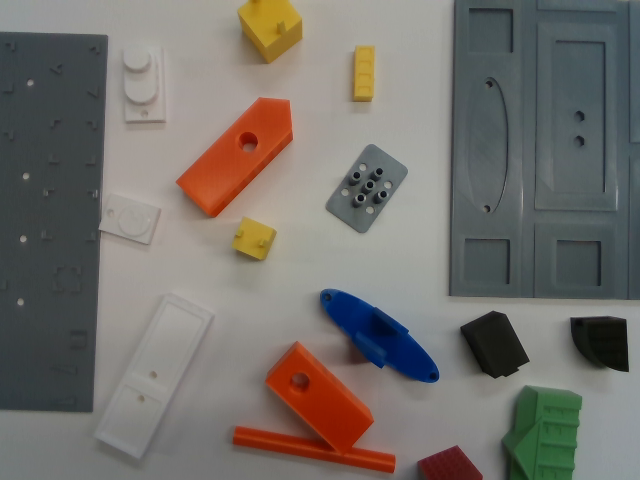

The image above is the first RGB view in the scan. The colored parts are fixed
on the work surface; only the camera changes viewpoint. Your goal is to recover
separate 2D detections and stable 3D tracks for these visible colored parts.

In [1]:
from pathlib import Path
import os
import cv2
import matplotlib.pyplot as plt
from exercise4_perception.scan_data import scan_frames

notebook_directory = Path.cwd()
default_workspace = notebook_directory.parent if notebook_directory.name == "notebooks" else notebook_directory
workspace = Path(os.environ.get("EXERCISE4_WORKSPACE", default_workspace)).expanduser().resolve()
BAG = Path(os.environ.get("EXERCISE4_BAG_PATH", workspace / "object_scan_001")).expanduser().resolve()
assert BAG.exists(), "Set EXERCISE4_BAG_PATH or place object_scan_001 in the workspace root."

task_frame = next(scan_frames(BAG))
print(f"Loaded RGB image: {task_frame['color'].shape}")

Loaded RGB image: (480, 640, 3)


[INFO] [1794902574.717323328] [rosbag2_storage]: Opened database '/home/skarrbuntu/Exercise4/object_scan_001/object_scan_001_0.db3' for READ_ONLY.


## Read selected RGB-D frames

The helper reads RGB, aligned depth, and CameraInfo directly from the bag. It associates 60 selected frames with a compact prerecorded camera trajectory so that observations can be compared in one fixed world frame.

**Theory:** the RGB image is the measurement in which we detect appearance. The
depth image supplies range for the same pixel locations, and the camera pose
places those measurements in a common `odom` frame. The packaged pose sequence
is an exercise input; you do not estimate odometry in this notebook.

Reference: [ROS 2 bag playback concepts](https://docs.ros.org/en/humble/Tutorials/Advanced/Recording-A-Bag-From-Your-Own-Node-Py.html).

[INFO] [1794902595.629196548] [rosbag2_storage]: Opened database '/home/skarrbuntu/Exercise4/object_scan_001/object_scan_001_0.db3' for READ_ONLY.


Loaded 60 selected RGB-D pairs from the ROS bag


[INFO] [1794902596.929435735] [rosbag2_storage]: Opened database '/home/skarrbuntu/Exercise4/object_scan_001/object_scan_001_0.db3' for READ_ONLY.


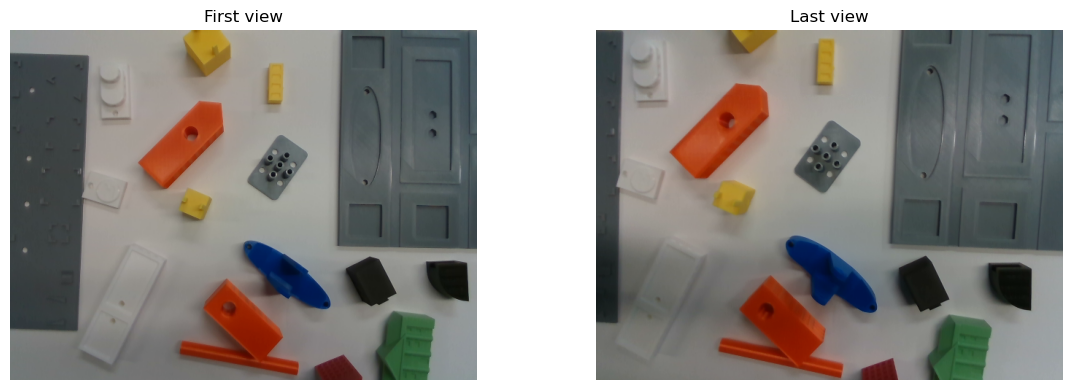

In [2]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np

from exercise4_perception.geometry import project_depth
from exercise4_perception.scan_data import load_scan_intrinsics, scan_frames, transform_points
from exercise4_perception.scan_notebook_checks import run_scan_checks, check_written_response
from exercise4_perception.reference_results import reference_result

frames = list(scan_frames(BAG))
intrinsics = load_scan_intrinsics(BAG)
print(f"Loaded {len(frames)} selected RGB-D pairs from the ROS bag")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, frame, title in zip(axes, (frames[0], frames[-1]), ("First view", "Last view")):
    axis.imshow(cv2.cvtColor(frame["color"], cv2.COLOR_BGR2RGB))
    axis.set_title(title); axis.axis("off")
plt.tight_layout()

## 1. Detect every colored pixel

Hue identifies a particular color, while saturation measures how far a pixel is from gray. Keeping the full hue range and thresholding saturation detects all vivid colors with one short function.

**Why this works:** HSV makes the color decision less coupled to brightness than
an RGB threshold. Low-saturation neutral objects are intentionally rejected;
lighting changes, shadows, and colorful background pixels are the main failure
modes.

References: [OpenCV color conversion](https://docs.opencv.org/4.x/d8/d01/group__imgproc__color__conversions.html) and [HSV color space](https://en.wikipedia.org/wiki/HSL_and_HSV).

In [8]:
def make_colored_mask(image_bgr, min_saturation=80, min_value=35):
    """Segment sufficiently vivid pixels from one BGR image.

    Args:
        image_bgr: uint8 NumPy array with shape (H, W, 3), in BGR order.
        min_saturation: Inclusive HSV saturation threshold in [0, 255].
        min_value: Inclusive HSV brightness threshold in [0, 255].
    Returns:
        uint8 binary array with shape (H, W), values 0 or 255.
    """
    # TODO 1 — Expected return: a uint8 HxW binary mask containing only 0 or 255.
    # Hint: cv2.inRange already returns exactly this type of mask.
    # Convert BGR to HSV, then retain every hue whose saturation and value exceed
    # the supplied limits.
    # Convert BGR image to HSV
    hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)

    # Define lower and upper HSV limits
    lower = (0, min_saturation, min_value)
    upper = (179, 255, 255)

    # Create binary mask
    mask = cv2.inRange(hsv, lower, upper)

    return mask

✓ all-color mask
Expected result: 35951 foreground pixels
Your result: 35951 foreground pixels


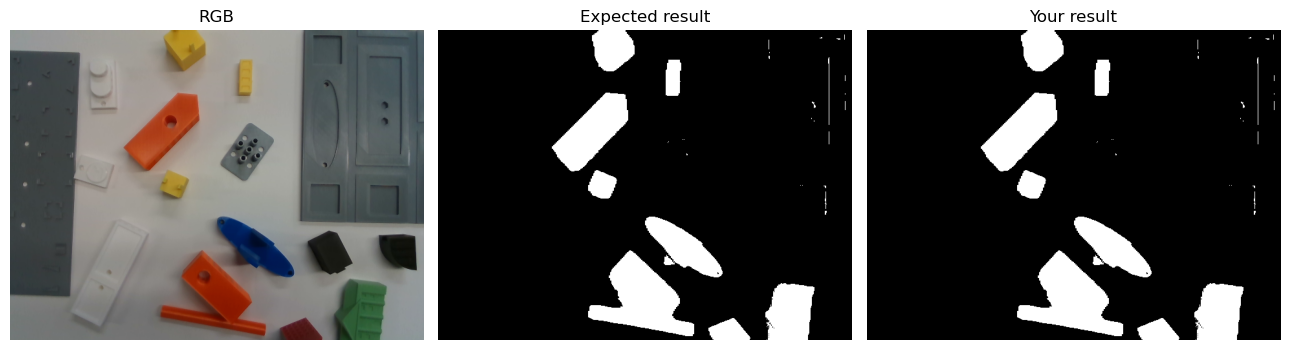

In [9]:
from exercise4_perception.scan_notebook_checks import check_make_colored_mask
check_make_colored_mask(make_colored_mask, show=False)

first = frames[0]
your_raw_mask = make_colored_mask(first["color"])
expected_raw_mask = reference_result("raw_mask")
print(f"Expected result: {np.count_nonzero(expected_raw_mask)} foreground pixels")
print(f"Your result: {np.count_nonzero(your_raw_mask)} foreground pixels")
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(cv2.cvtColor(first["color"], cv2.COLOR_BGR2RGB)); axes[0].set_title("RGB")
axes[1].imshow(expected_raw_mask, cmap="gray"); axes[1].set_title("Expected result")
axes[2].imshow(your_raw_mask, cmap="gray"); axes[2].set_title("Your result")
for axis in axes: axis.axis("off")
plt.tight_layout()

## 2. Clean the mask with morphology

Opening removes isolated colored specks. Closing fills small gaps within an object. Use a small elliptical kernel so nearby parts are less likely to merge.

**Theory:** erosion shrinks foreground regions and dilation expands them.
Opening removes features smaller than the kernel; closing repairs narrow holes or
breaks. The kernel size is therefore a scale assumption: too large a kernel can
join two objects.

Reference: [OpenCV morphological transformations](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html).

In [12]:
def clean_colored_mask(mask, kernel_size=5):
    """Clean an all-color binary mask with opening followed by closing.

    Args:
        mask: uint8 NumPy array with shape (H, W), values 0 or 255.
        kernel_size: Positive odd integer; ellipse width/height in pixels.
    Returns:
        uint8 array with shape (H, W), containing the cleaned binary mask.
    """
    # TODO 2 — Expected return: a uint8 mask with the same HxW shape as mask.
    # Hint: cv2.morphologyEx already preserves the mask type and shape.
    # Apply OPEN then CLOSE with an elliptical kernel so specks disappear and
    # small holes are filled.
    
    # Create elliptical kernel
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (kernel_size, kernel_size)
    )

    # Remove small white noise
    opened = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

    # Fill small black holes
    cleaned = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)

    return cleaned

✓ mask morphology
Expected result: 35618 foreground pixels
Your result: 35618 foreground pixels


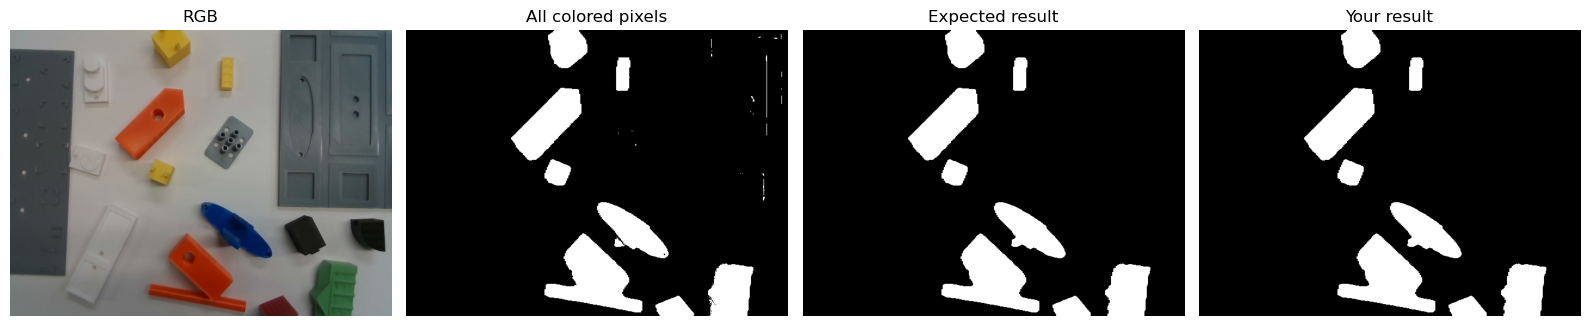

In [13]:
from exercise4_perception.scan_notebook_checks import check_clean_colored_mask
check_clean_colored_mask(clean_colored_mask, show=False)

raw_mask = your_raw_mask
cleaned_mask = clean_colored_mask(raw_mask)
expected_mask = reference_result("clean_mask")
print(f"Expected result: {np.count_nonzero(expected_mask)} foreground pixels")
print(f"Your result: {np.count_nonzero(cleaned_mask)} foreground pixels")
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(cv2.cvtColor(first["color"], cv2.COLOR_BGR2RGB)); axes[0].set_title("RGB")
axes[1].imshow(raw_mask, cmap="gray"); axes[1].set_title("All colored pixels")
axes[2].imshow(expected_mask, cmap="gray"); axes[2].set_title("Expected result")
axes[3].imshow(cleaned_mask, cmap="gray"); axes[3].set_title("Your result")
for axis in axes: axis.axis("off")
plt.tight_layout()

## 3. Separate all colored objects

Use 8-connectivity to group pixels that touch at edges or corners. Connected components assigns one integer label to each disconnected foreground region. Reject tiny regions by area and return one binary mask for every remaining object.

**Theory:** this is region-based detection. Touching objects become one component,
while an object split by a dark gap becomes several components. Area filtering is
a simple noise model rather than a learned classifier.

Reference: [OpenCV connected components](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html).

In [16]:
def extract_colored_components(mask, min_area=300):
    """Split one binary mask into filtered connected-component masks.

    Args:
        mask: uint8 NumPy array with shape (H, W), values 0 or 255.
        min_area: Minimum component area in pixels; background is excluded.
    Returns:
        List of uint8 (H, W) masks. Sort by increasing centroid u (horizontal
        pixel coordinate); if two u values are equal, sort by increasing v.
    """
    # TODO 3 — Expected return: a list of uint8 HxW masks, one per component.
    # Hint: cv2.connectedComponentsWithStats provides labels, area statistics,
    # and centroids. Ignore background label 0 and areas below min_area. Sort by
    # increasing centroid u (horizontal pixel coordinate). If two components
    # have the same u, place the one with the smaller v coordinate first.
    
    # Find connected components
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        mask, connectivity=8
    )

    components = []

    # Loop through all components (skip background label 0)
    for i in range(1, num_labels):

        # Get component area
        area = stats[i, cv2.CC_STAT_AREA]

        # Ignore small components
        if area < min_area:
            continue

        # Create binary mask for this component
        component_mask = (labels == i).astype(np.uint8) * 255

        # Get centroid coordinates
        u, v = centroids[i]

        # Store centroid and mask
        components.append((u, v, component_mask))

    # Sort by horizontal position, then vertical position
    components.sort(key=lambda item: (item[0], item[1]))

    # Return only the masks
    return [item[2] for item in components]

✓ multiple connected objects
Expected result: 8 components
Your result: 8 components


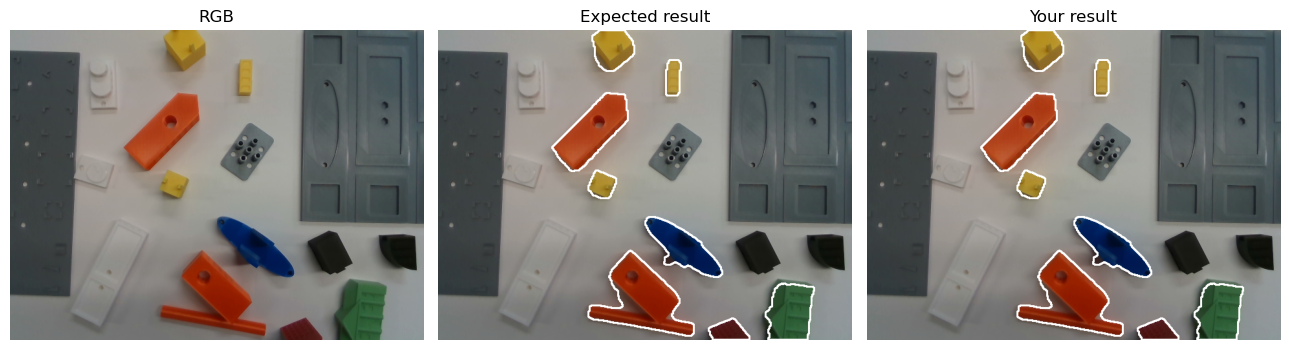

In [17]:
from exercise4_perception.scan_notebook_checks import check_extract_colored_components
check_extract_colored_components(extract_colored_components, show=False)

first_components = extract_colored_components(cleaned_mask)
expected_count = int(reference_result("component_count"))

def draw_component_contours(components):
    image = first["color"].copy()
    for component in components:
        contours, _ = cv2.findContours(component, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(image, contours, -1, (255, 255, 255), 2)
    return image

expected_preview = reference_result("component_preview")
your_preview = draw_component_contours(first_components)
print(f"Expected result: {expected_count} components")
print(f"Your result: {len(first_components)} components")
fig, axes = plt.subplots(1, 3, figsize=(13, 5))
axes[0].imshow(cv2.cvtColor(first["color"], cv2.COLOR_BGR2RGB)); axes[0].set_title("RGB")
axes[1].imshow(cv2.cvtColor(expected_preview, cv2.COLOR_BGR2RGB)); axes[1].set_title("Expected result")
axes[2].imshow(cv2.cvtColor(your_preview, cv2.COLOR_BGR2RGB)); axes[2].set_title("Your result")
for axis in axes: axis.axis("off")
plt.tight_layout()

## 4. Associate detections in the fixed world frame

The supplied helper below projects each component through aligned depth and the camera pose. Your function receives only the resulting 3D centers. Match the nearest valid pairs while ensuring that one old track cannot be assigned to two detections. Leave a new object as `None`; the supplied loop creates its ID.

**Function inputs**

- `previous_tracks`: a possibly empty dictionary with `N` entries, mapping each
  integer track ID to one NumPy array with shape `(3,)` containing its previous
  world-frame `[x, y, z]` position in metres;
- `current_centers`: a list with `M ≥ 0` NumPy arrays, each with shape `(3,)`,
  containing current world-frame `[x, y, z]` detections in metres;
- `max_distance`: a non-negative number giving the largest permitted 3D
  Euclidean movement in metres. The default `0.10` means 10 cm.

Return a Python list whose length is exactly `len(current_centers)`. Entry `i`
must be the integer track ID assigned to `current_centers[i]`, or `None` for a
new or unmatched detection. Preserve detection order and use each old track ID
at most once. Empty `current_centers` must return an empty list.

**Theory:** nearest-neighbor association is a greedy data-association method.
The distance gate rejects implausible jumps, and one-to-one assignment prevents
two detections from sharing an ID. We match in 3D because image positions change
when the camera moves. A Kalman filter plus Hungarian assignment would be more
robust, but would add complexity that is unnecessary for this controlled scan.

Reference: [OpenCV tracking concepts](https://docs.opencv.org/4.x/d9/df8/group__tracking.html).

In [21]:
def associate_detections(previous_tracks, current_centers, max_distance=0.10):
    """Associate current world-frame centers with existing tracks.

    Args:
        previous_tracks: Dict[int, ndarray shape (3,)] in metres.
        current_centers: List[ndarray shape (3,)] in metres; it may be empty.
        max_distance: Maximum accepted 3D Euclidean movement in metres.
    Returns:
        List[int | None] with len(current_centers), in detection order.
    """
    # TODO 4 — Expected return: a list containing one integer track ID or None
    # for each current center.
    # Hint: np.linalg.norm computes each Euclidean distance. Build
    # (distance, track_id, detection_index) candidates inside max_distance,
    # process nearest-first, and use each track and detection at most once.
    
    # Initially, no detections are matched
    matches = [None] * len(current_centers)

    # Store all possible matches
    candidates = []

    # Calculate distances between old tracks and new detections
    for track_id, old_center in previous_tracks.items():
        for i, new_center in enumerate(current_centers):

            distance = np.linalg.norm(old_center - new_center)

            if distance <= max_distance:
                candidates.append((distance, track_id, i))

    # Sort candidates from smallest distance to largest
    candidates.sort()

    # Keep track of already matched objects
    used_tracks = set()
    used_detections = set()

    # Assign the nearest valid pairs first
    for distance, track_id, i in candidates:

        if track_id not in used_tracks and i not in used_detections:

            matches[i] = track_id

            used_tracks.add(track_id)
            used_detections.add(i)

    return matches

✓ unique world-frame track association
Expected result: [9, 4, None]
Your result: [9, 4, None]


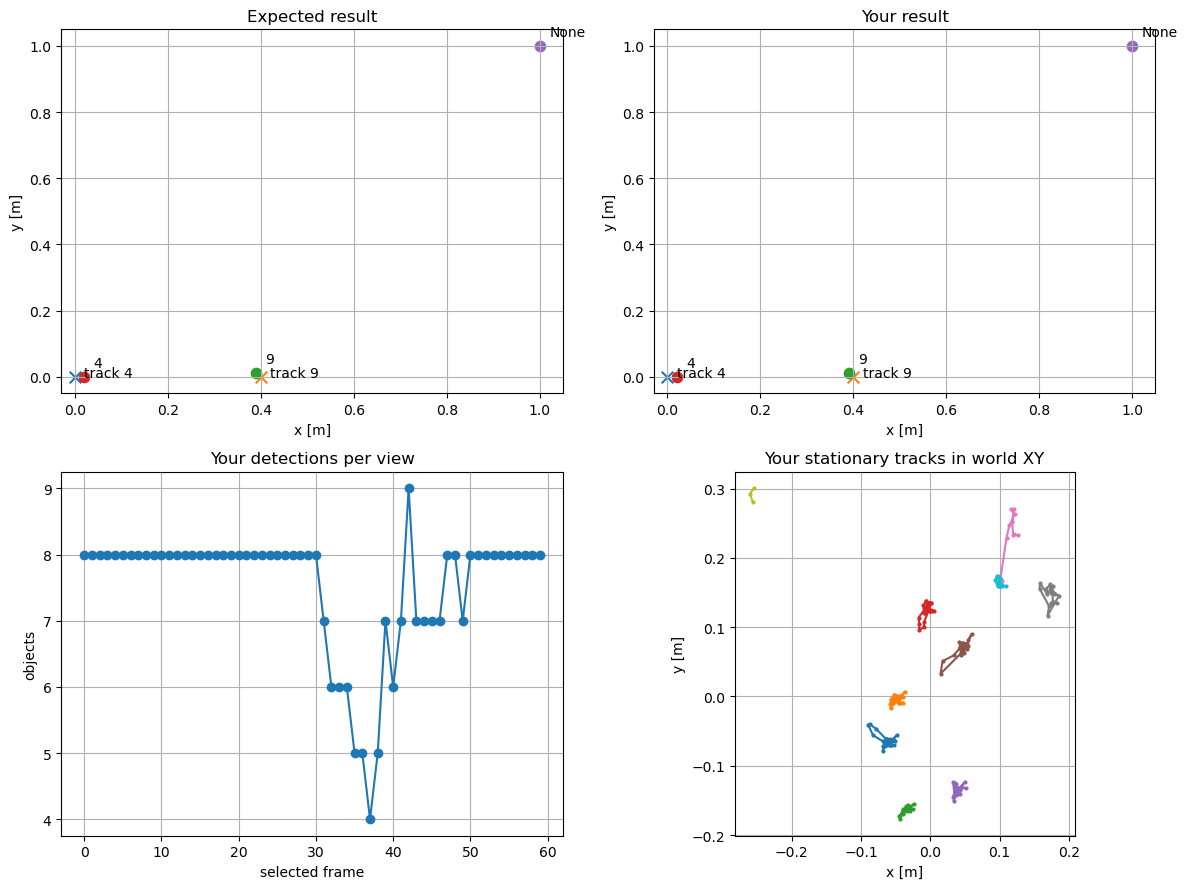

In [22]:
from exercise4_perception.scan_notebook_checks import check_associate_detections
check_associate_detections(associate_detections, show=False)

def world_detections(frame):
    clean = clean_colored_mask(make_colored_mask(frame["color"]))
    results = []
    for mask in extract_colored_components(clean):
        xyz, _, _ = project_depth(
            frame["depth"], intrinsics["fx"], intrinsics["fy"],
            intrinsics["cx"], intrinsics["cy"], intrinsics["depth_scale"],
            stride=3, mask=mask, max_depth=1.5,
        )
        if len(xyz) >= 20:
            world = transform_points(xyz, frame["pose"])
            results.append(np.median(world, axis=0))
    return results

known_tracks, histories, next_track_id = {}, {}, 0
detection_counts = []
for frame in frames:
    centers = world_detections(frame)
    detection_counts.append(len(centers))
    assignments = associate_detections(known_tracks, centers)
    for track_id, center in zip(assignments, centers):
        if track_id is None:
            track_id = next_track_id
            next_track_id += 1
            histories[track_id] = []
        known_tracks[track_id] = center
        histories[track_id].append(center)

test_previous = {4: np.array([0.0, 0.0, 0.5]), 9: np.array([0.4, 0.0, 0.5])}
test_current = [np.array([0.39, 0.01, 0.5]),
                np.array([0.02, 0.0, 0.5]),
                np.array([1.0, 1.0, 1.0])]
expected_assignments = [9, 4, None]
your_assignments = associate_detections(test_previous, test_current, 0.10)
print(f"Expected result: {expected_assignments}")
print(f"Your result: {your_assignments}")

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for axis, assignments, title in (
    (axes[0, 0], expected_assignments, "Expected result"),
    (axes[0, 1], your_assignments, "Your result"),
):
    for track_id, point in test_previous.items():
        axis.scatter(point[0], point[1], marker="x", s=70)
        axis.text(point[0] + 0.02, point[1], f"track {track_id}")
    for index, point in enumerate(test_current):
        axis.scatter(point[0], point[1], s=55)
        axis.text(point[0] + 0.02, point[1] + 0.03, str(assignments[index]))
    axis.set_xlabel("x [m]"); axis.set_ylabel("y [m]"); axis.grid(True); axis.set_title(title)

axes[1, 0].plot(detection_counts, "o-"); axes[1, 0].set_title("Your detections per view")
axes[1, 0].set_xlabel("selected frame"); axes[1, 0].set_ylabel("objects"); axes[1, 0].grid(True)
for track_id, history in histories.items():
    points = np.asarray(history)
    if len(points) >= 3:
        axes[1, 1].plot(points[:, 0], points[:, 1], "o-", ms=2)
axes[1, 1].set_aspect("equal"); axes[1, 1].grid(True)
axes[1, 1].set_title("Your stationary tracks in world XY")
axes[1, 1].set_xlabel("x [m]"); axes[1, 1].set_ylabel("y [m]")
plt.tight_layout()

In [23]:
run_scan_checks(make_colored_mask, clean_colored_mask,
                extract_colored_components, associate_detections)

✓ all-color mask
✓ mask morphology
✓ multiple connected objects
✓ unique world-frame track association
All exercise checks passed.


## 5. Export your tested functions for ROS 2

The supplied ROS node imports these exact functions. Your segmentation, morphology, component extraction, and association therefore control all 2D masks, 3D object clouds, boxes, and trajectories in RViz.

In [24]:
from exercise4_perception.notebook_export import export_notebook_functions, load_module_file

function_names = (
    "make_colored_mask", "clean_colored_mask",
    "extract_colored_components", "associate_detections",
)
module_path = export_notebook_functions(
    workspace / "src" / "exercise4_perception" / "workspace" / "scan_algorithms.py",
    function_names=function_names,
)
exported = load_module_file(module_path)
run_scan_checks(exported.make_colored_mask, exported.clean_colored_mask,
                exported.extract_colored_components, exported.associate_detections)
print(f"Exported moving-camera algorithms to {module_path}")

✓ all-color mask
✓ mask morphology
✓ multiple connected objects
✓ unique world-frame track association
All exercise checks passed.
Exported moving-camera algorithms to /home/skarrbuntu/Exercise4/src/exercise4_perception/workspace/scan_algorithms.py


## 6. Compare with a pre-built detector

`cv2.SimpleBlobDetector` is useful here because it accepts the cleaned binary mask and returns all blob centers and approximate sizes without a learned model. It is a fair classical comparison for custom parts that are absent from generic object-detector class lists. It does not produce exact masks and may merge touching parts.

**How to interpret it:** the detector searches connected foreground structure and
fits compact keypoints; the magenta circles are an approximation, not an object
boundary. This shows why a pre-built tool can be convenient while still depending
on preprocessing and assumptions about shape.

Reference: [OpenCV SimpleBlobDetector](https://docs.opencv.org/4.x/d0/d7a/classcv_1_1SimpleBlobDetector.html).

SimpleBlobDetector returned 8 blobs


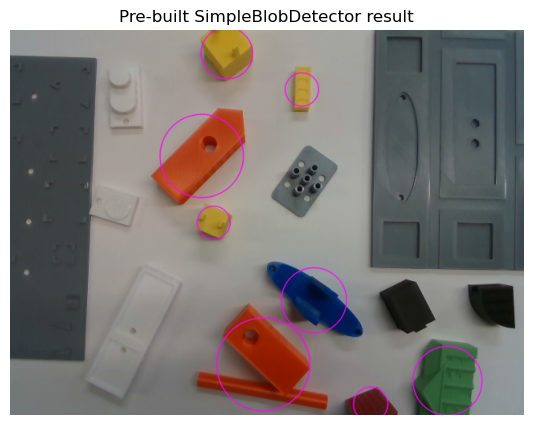

In [25]:
parameters = cv2.SimpleBlobDetector_Params()
parameters.minThreshold = 1
parameters.maxThreshold = 256
parameters.filterByColor = True
parameters.blobColor = 255
parameters.filterByArea = True
parameters.minArea = 300
parameters.maxArea = 50000
parameters.filterByCircularity = False
parameters.filterByConvexity = False
parameters.filterByInertia = False
blob_detector = cv2.SimpleBlobDetector_create(parameters)
keypoints = blob_detector.detect(cleaned_mask)
blob_preview = cv2.drawKeypoints(
    first["color"], keypoints, None, (255, 0, 255),
    cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS,
)
print(f"SimpleBlobDetector returned {len(keypoints)} blobs")
plt.figure(figsize=(8, 5)); plt.imshow(cv2.cvtColor(blob_preview, cv2.COLOR_BGR2RGB))
plt.axis("off"); plt.title("Pre-built SimpleBlobDetector result");

In [28]:
detector_comparison = """
Both methods detected 8 objects. Connected components provide accurate
binary masks and object boundaries, but touching objects can be merged into
one component. SimpleBlobDetector is easy to use and provides approximate
object centers and sizes, but its circular representations do not match
irregular object shapes and nearby objects may be merged.
"""

In [29]:
check_written_response(detector_comparison, min_length=100)


Both methods detected 8 objects. Connected components provide accurate
binary masks and object boundaries, but touching objects can be merged into
one component. SimpleBlobDetector is easy to use and provides approximate
object centers and sizes, but its circular representations do not match
irregular object shapes and nearby objects may be merged.



## 7. Supplied RViz visualization

The complete RViz visualization is already implemented. You do **not** write ROS
publishers, point-cloud code, markers, transforms, or an RViz configuration.
Your only steps are to run the export cell above and start the supplied launch
file below.

The supplied ROS node imports your four exported functions, projects every
accepted component through aligned depth, transforms it into `odom`, and
maintains a separate track. Camera poses are used internally and are not
visualized.

From the extracted exercise directory:

```bash
source ./activate_workspace.sh

ros2 launch exercise4_perception scan_object_tracking_rviz.launch.py \
  "bag_path:=${EXERCISE4_BAG_PATH}" \
  algorithm_module:=workspace.scan_algorithms
```

Complete the observation cell below after watching the visualization.

In [30]:
rviz_observation = """
The objects change positions in the RGB images as the camera moves,
but their 3D tracks remain approximately stationary in the fixed world
frame. As the camera moves, additional objects become visible and
receive new tracking IDs. Some tracks may become broken or duplicated
because of occlusions, inaccurate depth measurements, or distances
exceeding the nearest-neighbor matching threshold.
"""

In [31]:
check_written_response(rviz_observation, min_length=80)


The objects change positions in the RGB images as the camera moves,
but their 3D tracks remain approximately stationary in the fixed world
frame. As the camera moves, additional objects become visible and
receive new tracking IDs. Some tracks may become broken or duplicated
because of occlusions, inaccurate depth measurements, or distances
exceeding the nearest-neighbor matching threshold.



## 8. Bonus exercise

Track moving objects using your own ROS bag, a recording obtained online, or
the supplied secondary ROS bag. The recording must include moving objects,
RGB images, aligned depth, and camera calibration.

Adapt your four detection and tracking functions as needed. Implement a complete
ROS 2 node that subscribes to the RGB, aligned-depth, and camera-info topics,
calls your functions, and publishes object tracks with consistent IDs across
frames.

Visualize the detections on the RGB feed and the corresponding 3D tracks in
RViz. Use the supplied visualization node as an implementation reference and
`scan_object_tracking_rviz.launch.py` as a launch-file template.


### Submission

Submit the notebook after all four checks pass, every expected-versus-your-result
figure is visible, both written responses are complete, and the export cell has
created the algorithm module.